In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

def load_dataset(filename):
    BASE_DIR = './data'
    EXTENSION = '.csv'
    TARGET_PATH = f'{BASE_DIR}/{filename}{EXTENSION}'
    try:
        return pd.read_csv(TARGET_PATH)
    except FileNotFoundError:
        return None
    except UnicodeDecodeError:
        return pd.read_csv(TARGET_PATH, encoding = 'euc-kr')

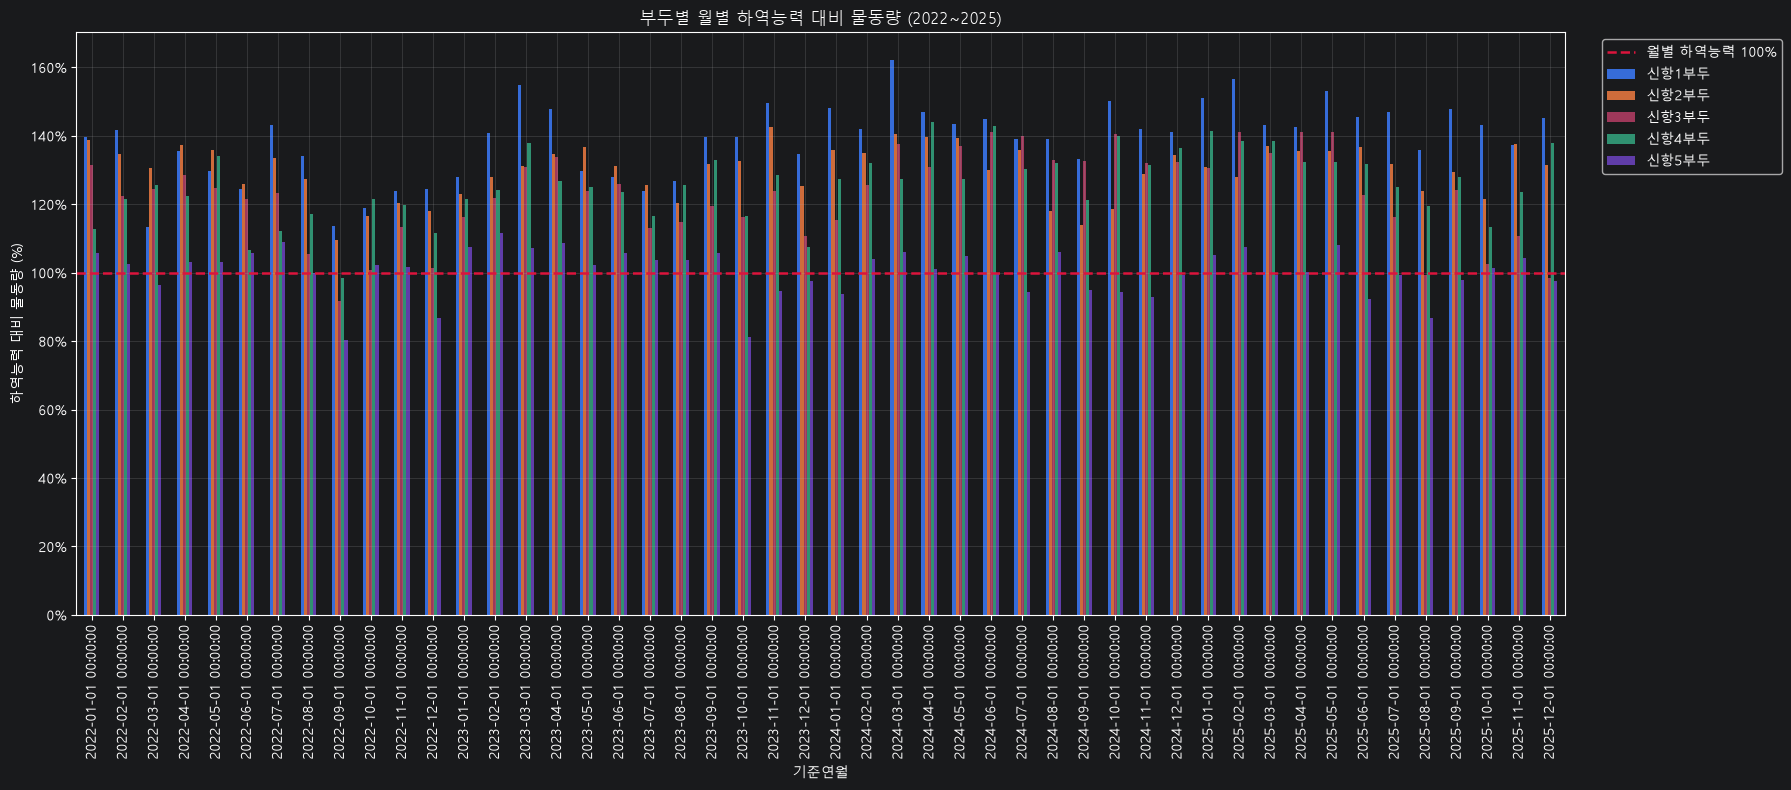

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

df = pd.read_csv("../data/port_month.csv", encoding="cp949")

# 연간 하역능력 (단위: 천TEU)
annual_capacity = pd.Series({
    "신항1부두": 2090,
    "신항2부두": 3790,
    "신항3부두": 2310,
    "신항4부두": 1930,
    "신항5부두": 2440,
    # "신항6부두": 1950,
    # "신항7부두": 1950,
})

# 기준년도와 월을 날짜로 변환
df["기준연월"] = pd.to_datetime({
    "year": df["기준년도"],
    "month": df["월"],
    "day": 1,
})

# 분석 기간 선택
df = df[
    df["기준연월"].between("2022-01-01", "2025-12-01")
].copy()

# 기준을 정할 부두
df = df[['기준연월','기준년도','월','신항1부두','신항2부두','신항3부두','신항4부두','신항5부두']]

# 월별 물동량: 행은 기준연월, 열은 부두
monthly_volume = (
    df.set_index("기준연월")[annual_capacity.index]
      .sort_index()
      .reindex(pd.date_range("2022-01-01", "2025-12-01", freq="MS"))
)
monthly_volume.index.name = "기준연월"

# 각 월의 일수와 해당 연도의 총일수
month_days = pd.Series(
    monthly_volume.index.days_in_month,
    index=monthly_volume.index,
)

year_days = pd.Series(
    365 + monthly_volume.index.is_leap_year.astype(int),
    index=monthly_volume.index,
)

# 월별 하역능력 = 연간 하역능력 × 월 일수 / 연 일수
monthly_capacity = pd.DataFrame(
    1.0,
    index=monthly_volume.index,
    columns=annual_capacity.index,
).mul(annual_capacity, axis="columns").mul(
    month_days / year_days,
    axis="index",
)

# 월별 하역능력 대비 물동량 비율 (%)
ratio_table = monthly_volume.div(monthly_capacity).mul(100)

# 5개 부두를 한 그래프에 표시
ax = ratio_table.plot.bar(
    figsize=(18, 8),
)

# # 5개 부두를 한 그래프에 표시
# ax = ratio_table.plot(
#     figsize=(18, 8),
#     marker="o",
#     markersize=3,
#     linewidth=1.8,
# )

ax.axhline(
    100,
    color="crimson",
    linestyle="--",
    linewidth=1.8,
    label="월별 하역능력 100%",
)

ax.set_title("부두별 월별 하역능력 대비 물동량 (2022~2025)")
ax.set_xlabel("기준연월")
ax.set_ylabel("하역능력 대비 물동량 (%)")
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))

ax.grid(alpha=0.25)
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1))

plt.tight_layout()
plt.show()

# 계산 결과 확인
# print("월별 하역능력 (천TEU)")
# display(monthly_capacity.round(2))
#
# print("월별 하역능력 대비 물동량 (%)")
# display(ratio_table.round(2))